# Bragg signal clustering, aliens and background

This notebook separates the Bragg signal of a particle from an alien peak
and from a smooth background, with `cdiutils.utils.cluster_bragg_signal`
(E. Bellec's DBSCAN clustering,
https://github.com/ewbellec/alienclustering) and
`cdiutils.utils.background_map`.

The data are synthetic: a faceted crystal (box) whose Bragg peak has
fringes and facet streaks, a weak alien peak, and a background that varies
across the detector but not with the rocking angle. Axis 0 plays the role
of the rocking axis.

See the user guide page *Bragg Signal Clustering, Aliens and Background*.

In [1]:
# imports
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import binary_dilation, distance_transform_edt

from cdiutils.simulation import make_box, simulate_diffraction
from cdiutils.utils import background_map, cluster_bragg_signal

In [2]:
# synthetic scan: Bragg peak of a box, an alien, a detector background
shape = (64, 96, 96)
crystal = make_box(shape, dimensions=(16, 20, 24))
bragg = simulate_diffraction(crystal, photon_budget=2e7,
                             poisson_statistics=False)

# weak alien peak far from the Bragg peak (another particle)
z, y, x = np.indices(shape)
alien = 40 * np.exp(-((z - 12) ** 2 + (y - 15) ** 2 + (x - 80) ** 2)
                    / (2 * 1.5 ** 2))

# background: smooth in the detector plane, constant over the rocking
rows, columns = np.indices(shape[1:])
background_true = 0.2 + 0.3 * np.exp(
    -((rows - 48) ** 2 + (columns - 48) ** 2) / (2 * 30 ** 2))

expected = bragg + alien + background_true[None]
data = np.random.default_rng(0).poisson(expected).astype(float)
mask = np.zeros(shape, dtype=bool)
print(f"{data.sum():.3g} photons, maximum {data.max():.0f}")

2.02e+07 photons, maximum 259937


## 1. Clustering, with and without fringe merging

Without merging, the fringe shells and facet streaks of the peak come out
as many separate clusters, which would be mistaken for aliens.
`merge_size` (a maximum filter before DBSCAN, below the fringe spacing)
joins them to the Bragg cluster.

In [3]:
# cluster the same data without and with merging
for merge_size in (1, 3, 5):
    labels, bragg_label, region = cluster_bragg_signal(
        data, threshold=0.3, merge_size=merge_size, mask=mask)
    clusters = len(np.unique(labels)) - 1
    print(f"merge_size {merge_size}: {clusters} clusters, "
          f"Bragg cluster {np.sum(labels == bragg_label)} voxels")

merge_size 1: 120 clusters, Bragg cluster 1546 voxels
merge_size 3: 21 clusters, Bragg cluster 28113 voxels


merge_size 5: 2 clusters, Bragg cluster 44174 voxels


In [4]:
# keep merge_size = 5; aliens = separate clusters far from the Bragg region
labels, bragg_label, region = cluster_bragg_signal(
    data, threshold=0.3, merge_size=5, dilation=3, mask=mask)
sizes = np.bincount(labels.ravel())
distance = distance_transform_edt(~region)
aliens = [
    k for k in range(1, sizes.size)
    if k != bragg_label and sizes[k] >= 20
    and distance[labels == k].min() > 10
]
alien_mask = binary_dilation(np.isin(labels, aliens), iterations=3)
alien_mask &= ~region
print("alien clusters:", aliens,
      "| alien at (12, 15, 80) masked:", bool(alien_mask[12, 15, 80]))

alien clusters: [2] | alien at (12, 15, 80) masked: True


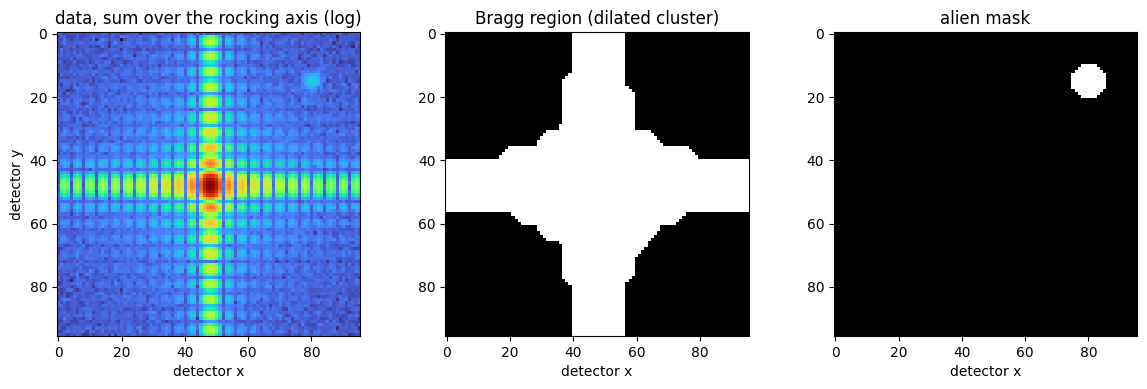

In [5]:
# projections: data, Bragg region and alien mask
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].imshow(np.log10(data.sum(axis=0) + 1), cmap="turbo")
axes[0].set_title("data, sum over the rocking axis (log)")
axes[1].imshow(region.any(axis=0), cmap="gray")
axes[1].set_title("Bragg region (dilated cluster)")
axes[2].imshow(alien_mask.any(axis=0), cmap="gray")
axes[2].set_title("alien mask")
for axis in axes:
    axis.set_xlabel("detector x")
axes[0].set_ylabel("detector y")
fig.tight_layout()

## 2. Background map

The background is estimated per detector pixel from the frames where the
pixel is outside the Bragg region. With `pure_pixels=False` a pixel also
contributes from frames where weak fringes cross it, and the map is
overestimated near the peak; `pure_pixels=True` uses only pixels that are
outside the region in every frame and fills the rest by smoothing.

In [6]:
# background maps against the true background
excluded = region | alien_mask
leaky = background_map(data, excluded, mask=mask, sigma=10)
pure = background_map(data, excluded, mask=mask, sigma=10,
                      pure_pixels=True)
near_peak = (slice(38, 58), slice(38, 58))
for name, estimate in (("all usable frames", leaky), ("pure pixels", pure)):
    error = estimate[near_peak] - background_true[near_peak]
    print(f"{name:18s}: mean error near the peak "
          f"{error.mean():+.3f} photon/pixel/frame")

all usable frames : mean error near the peak +0.276 photon/pixel/frame
pure pixels       : mean error near the peak +0.062 photon/pixel/frame


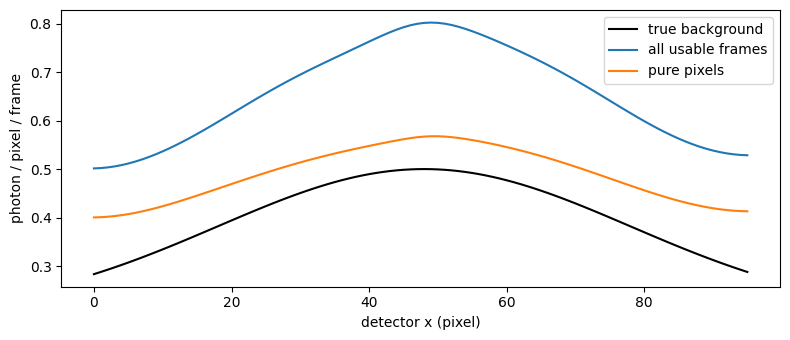

In [7]:
# profile through the peak along detector x
fig, axis = plt.subplots(figsize=(8, 3.5))
axis.plot(background_true[48], "k", label="true background")
axis.plot(leaky[48], label="all usable frames")
axis.plot(pure[48], label="pure pixels")
axis.set_xlabel("detector x (pixel)")
axis.set_ylabel("photon / pixel / frame")
axis.legend()
fig.tight_layout()

## 3. Inputs for phase retrieval

Subtract the map, mask (never zero) the aliens, and keep everything else:
the weak fringes outside the Bragg region still carry the resolution.

In [8]:
# cleaned intensity and mask for PyNX
cleaned = np.clip(data - pure[None], 0, None)
phasing_mask = (mask | alien_mask).astype(np.int8)
print(f"background removed: {(data - cleaned).sum():.3g} photons; "
      f"masked voxels: {phasing_mask.sum()}")

background removed: 9.69e+04 photons; masked voxels: 763
